# Análise de Viés Algorítmico em Seleção de Candidatos (XAI)
### Etapa 6: Métricas de Desempenho (AUC-ROC), Equidade (Fairness) e Variáveis Proxy

Esta etapa complementa as anteriores com três itens:

1. **AUC-ROC** do classificador.
2. **Métricas de equidade** por gênero, raça e faixa etária:
   - *Taxa de seleção*: percentual de candidatos aprovados em cada grupo.
   - *Disparate Impact (DI)*: taxa do grupo com menor aprovação dividida pela do grupo com maior aprovação. Valores abaixo de 0,80 são o limiar de referência usado para indicar impacto desproporcional (regra dos quatro quintos).
   - *Diferença de paridade demográfica (DPD)*: diferença entre a maior e a menor taxa de seleção.
   - *Oportunidade igual*: entre os candidatos que de fato mereciam aprovação nos dados, quantos o modelo aprova em cada grupo (TPR).
3. **Checagem de variáveis proxy**: algum cargo ou a idade funcionam como substitutos do gênero ou da raça?

As métricas de equidade são calculadas em dois níveis: nos **dados reais** (o viés que já existe na base) e nas **previsões do modelo** (o que o modelo reproduz ou amplifica).

## 1. Carregar modelo e dados

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import os
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import chi2_contingency

PASTA_DADOS = 'dados'

modelo = joblib.load(os.path.join(PASTA_DADOS, 'modelo_random_forest.pkl'))
X_test = pd.read_csv(os.path.join(PASTA_DADOS, 'X_test.csv'), index_col=0)
y_test = pd.read_csv(os.path.join(PASTA_DADOS, 'y_test.csv'), index_col=0).squeeze()
df = pd.read_csv(os.path.join(PASTA_DADOS, 'recruitment_data_fixed.csv'))

bins = [24, 34, 44, 55]
labels = ['25-34', '35-44', '45-55']
df['Faixa'] = pd.cut(df['Age'], bins=bins, labels=labels)

print('X_test:', X_test.shape, '| base completa:', df.shape)

X_test: (2000, 54) | base completa: (10000, 10)


## 2. AUC-ROC

AUC-ROC: 0.842


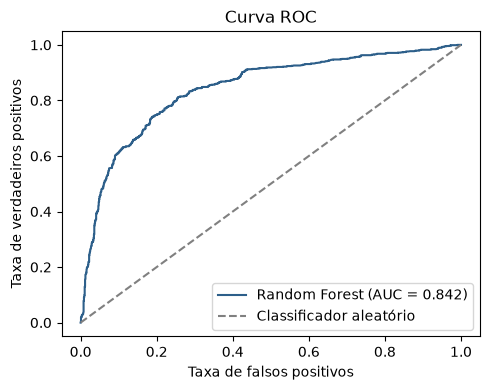

In [2]:
prob = modelo.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, prob)
print(f'AUC-ROC: {auc:.3f}')

fpr, tpr, _ = roc_curve(y_test, prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, color='#2d5f8a', label=f'Random Forest (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Classificador aleatório')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'curva_roc.png'), dpi=150)
plt.show()

## 3. Função para calcular as métricas de equidade

In [3]:
def equidade(tabela, coluna_grupo, coluna_alvo):
    taxas = tabela.groupby(coluna_grupo, observed=True)[coluna_alvo].mean()
    di = taxas.min() / taxas.max()
    dpd = taxas.max() - taxas.min()
    return taxas, di, dpd

def relatorio(tabela, coluna_alvo, titulo):
    print(titulo)
    for grupo in ['Gender', 'Race', 'Faixa']:
        taxas, di, dpd = equidade(tabela, grupo, coluna_alvo)
        taxas_txt = ', '.join(f'{k}: {v*100:.1f}%' for k, v in taxas.items())
        situacao = 'ABAIXO de 0,80' if di < 0.8 else 'dentro do limiar'
        print(f'  {grupo:7s} | {taxas_txt}')
        print(f'          | DI = {di:.3f} ({situacao}) | DPD = {dpd*100:.1f} p.p.')
    print()

## 4. Equidade nos dados reais (base completa)

In [4]:
relatorio(df, 'Best Match', 'DADOS REAIS (10.000 candidatos)')

DADOS REAIS (10.000 candidatos)
  Gender  | Female: 35.4%, Male: 61.3%
          | DI = 0.579 (ABAIXO de 0,80) | DPD = 25.8 p.p.
  Race    | Mongoloid/Asian: 48.8%, Negroid/Black: 48.6%, White/Caucasian: 48.1%
          | DI = 0.985 (dentro do limiar) | DPD = 0.7 p.p.
  Faixa   | 25-34: 48.3%, 35-44: 47.8%, 45-55: 49.4%
          | DI = 0.967 (dentro do limiar) | DPD = 1.6 p.p.



## 5. Equidade nas previsões do modelo (conjunto de teste)

In [5]:
atributos = df.loc[X_test.index, ['Gender', 'Age', 'Race', 'Faixa']].copy()
atributos['real'] = y_test.values
atributos['previsto'] = modelo.predict(X_test)

relatorio(atributos, 'real', 'DADOS REAIS (apenas o conjunto de teste)')
relatorio(atributos, 'previsto', 'PREVISÕES DO MODELO (conjunto de teste)')

DADOS REAIS (apenas o conjunto de teste)
  Gender  | Female: 37.9%, Male: 58.5%
          | DI = 0.648 (ABAIXO de 0,80) | DPD = 20.6 p.p.
  Race    | Mongoloid/Asian: 47.4%, Negroid/Black: 51.0%, White/Caucasian: 47.2%
          | DI = 0.925 (dentro do limiar) | DPD = 3.8 p.p.
  Faixa   | 25-34: 45.5%, 35-44: 50.9%, 45-55: 49.1%
          | DI = 0.895 (dentro do limiar) | DPD = 5.3 p.p.

PREVISÕES DO MODELO (conjunto de teste)
  Gender  | Female: 15.1%, Male: 72.4%
          | DI = 0.208 (ABAIXO de 0,80) | DPD = 57.3 p.p.
  Race    | Mongoloid/Asian: 41.6%, Negroid/Black: 48.2%, White/Caucasian: 43.7%
          | DI = 0.862 (dentro do limiar) | DPD = 6.6 p.p.
  Faixa   | 25-34: 43.5%, 35-44: 44.4%, 45-55: 45.4%
          | DI = 0.958 (dentro do limiar) | DPD = 1.9 p.p.



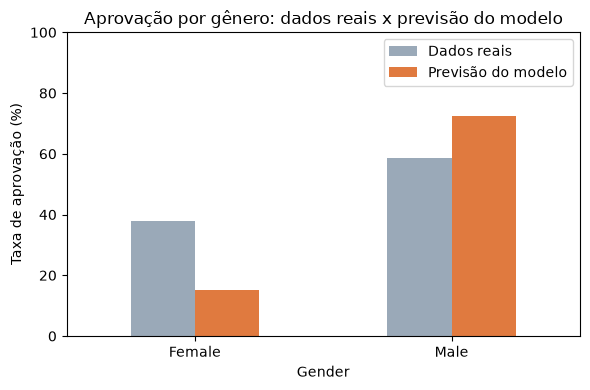

        Dados reais  Previsão do modelo
Gender                                 
Female         37.9                15.1
Male           58.5                72.4


In [6]:
taxas = pd.DataFrame({
    'Dados reais': atributos.groupby('Gender')['real'].mean() * 100,
    'Previsão do modelo': atributos.groupby('Gender')['previsto'].mean() * 100
})

taxas.plot(kind='bar', figsize=(6, 4), color=['#9aa9b8', '#e07a3f'])
plt.ylabel('Taxa de aprovação (%)')
plt.title('Aprovação por gênero: dados reais x previsão do modelo')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'equidade_genero_real_vs_previsto.png'), dpi=150)
plt.show()
print(taxas.round(1))

## 6. Oportunidade igual (por gênero)

Entre os candidatos que **foram aprovados nos dados reais**, que percentual o modelo também aprova (TPR)? Entre os que **não foram aprovados**, que percentual o modelo aprova mesmo assim (FPR)?

In [7]:
aprovados_reais = atributos[atributos['real'] == 1]
reprovados_reais = atributos[atributos['real'] == 0]

tpr_g = aprovados_reais.groupby('Gender')['previsto'].mean()
fpr_g = reprovados_reais.groupby('Gender')['previsto'].mean()

print('TPR (aprovados reais que o modelo também aprova):')
print((tpr_g * 100).round(1).to_string())
print()
print('FPR (reprovados reais que o modelo aprova mesmo assim):')
print((fpr_g * 100).round(1).to_string())
print()
print(f'Diferença de oportunidade igual (TPR homem - TPR mulher): {(tpr_g["Male"] - tpr_g["Female"])*100:.1f} p.p.')

TPR (aprovados reais que o modelo também aprova):
Gender
Female    35.1
Male      95.2

FPR (reprovados reais que o modelo aprova mesmo assim):
Gender
Female     2.8
Male      40.2

Diferença de oportunidade igual (TPR homem - TPR mulher): 60.0 p.p.


## 7. Checagem de variáveis proxy

Se algum cargo (ou a idade) estivesse fortemente associado ao gênero ou à raça, o modelo poderia discriminar de forma indireta. Testamos a associação com o teste qui-quadrado (p < 0,05 indicaria associação significativa) e a correlação entre idade e gênero.

In [8]:
p_cargo_genero = chi2_contingency(pd.crosstab(df['Job Roles'], df['Gender']))[1]
p_cargo_raca = chi2_contingency(pd.crosstab(df['Job Roles'], df['Race']))[1]
corr_idade_genero = df['Age'].corr(df['Gender'].eq('Male').astype(int))

print(f'Cargo x Gênero: p = {p_cargo_genero:.4f}')
print(f'Cargo x Raça:   p = {p_cargo_raca:.4f}')
print(f'Correlação Idade x Gênero: {corr_idade_genero:.3f}')

prop_homens = (df.groupby('Job Roles')['Gender'].apply(lambda s: s.eq('Male').mean()) * 100)
print(f'\nProporção de homens por cargo: de {prop_homens.min():.1f}% a {prop_homens.max():.1f}% (média geral: {df["Gender"].eq("Male").mean()*100:.1f}%)')

Cargo x Gênero: p = 0.1109
Cargo x Raça:   p = 0.8750
Correlação Idade x Gênero: 0.006

Proporção de homens por cargo: de 40.5% a 56.9% (média geral: 50.6%)
